Images : 1797   Pixels per image : 64   Classes : [0 1 2 3 4 5 6 7 8 9]


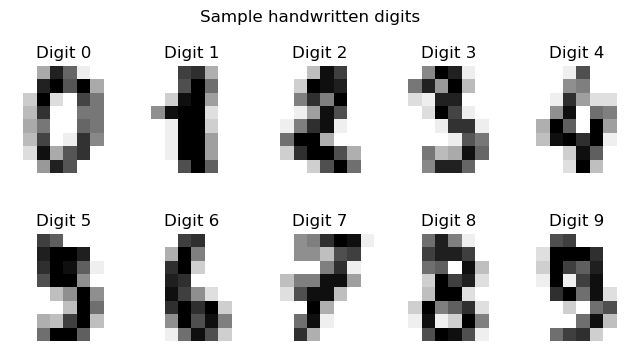


Kernel comparison:
          Train accuracy  Test accuracy
Kernel                                
linear           1.0000         0.9800
poly             0.9807         0.9711
rbf              0.9978         0.9800
sigmoid          0.9614         0.9467

Best parameters : {'C': 10, 'gamma': 'scale'}
Best cross-validation accuracy : 0.9859

Test accuracy : 0.9800

Classification report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        45
           1       0.96      0.98      0.97        46
           2       1.00      1.00      1.00        44
           3       1.00      1.00      1.00        46
           4       0.96      0.98      0.97        45
           5       0.98      0.98      0.98        46
           6       0.98      1.00      0.99        45
           7       0.96      0.98      0.97        45
           8       1.00      0.93      0.96        43
           9       0.98      0.96      0.97        45

    accuracy 

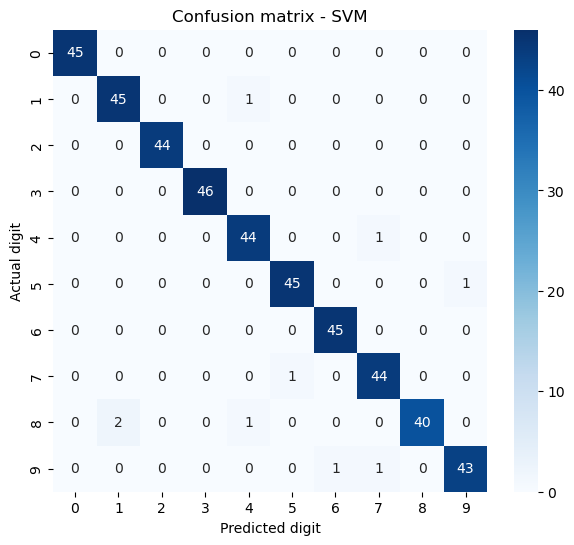

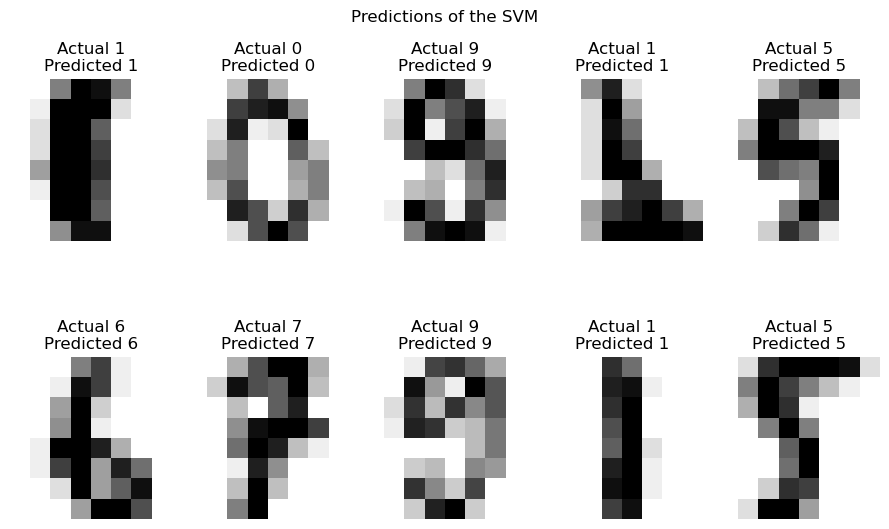

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
 
# ---------------- 1. Load the dataset ----------------
digits = load_digits()
X, y = digits.data, digits.target
print("Images :", X.shape[0], "  Pixels per image :", X.shape[1], "  Classes :", np.unique(y))
 
# show some sample images
fig, axes = plt.subplots(2, 5, figsize=(8, 4))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap='gray_r'); ax.set_title(f'Digit {label}'); ax.axis('off')
plt.suptitle('Sample handwritten digits'); plt.show()
 
# ---------------- 2. Split and scale ----------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
 
# ---------------- 3. Compare SVM kernels ----------------
rows = []
for kernel in ['linear', 'poly', 'rbf', 'sigmoid']:
    clf = SVC(kernel=kernel)
    clf.fit(X_train_s, y_train)
    rows.append({'Kernel': kernel,
                 'Train accuracy': clf.score(X_train_s, y_train),
                 'Test accuracy' : clf.score(X_test_s, y_test)})
print("\nKernel comparison:\n", pd.DataFrame(rows).set_index('Kernel').round(4))
 
# ---------------- 4. Tune C and gamma of the RBF kernel ----------------
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': ['scale', 0.001, 0.01]}
grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, n_jobs=-1)
grid.fit(X_train_s, y_train)
print("\nBest parameters :", grid.best_params_)
print("Best cross-validation accuracy : %.4f" % grid.best_score_)
 
# ---------------- 5. Final model and evaluation ----------------
best_svm = grid.best_estimator_
y_pred = best_svm.predict(X_test_s)
print("\nTest accuracy : %.4f" % accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))
 
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted digit'); plt.ylabel('Actual digit'); plt.title('Confusion matrix - SVM')
plt.show()
 
# ---------------- 6. Predict a few test images ----------------
fig, axes = plt.subplots(2, 5, figsize=(9, 5.5))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(X_test[i].reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Actual {y_test[i]}\nPredicted {y_pred[i]}'); ax.axis('off')
plt.suptitle('Predictions of the SVM')
plt.tight_layout(); plt.subplots_adjust(hspace=0.45, top=0.88); plt.show()
